In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
!pip list 2>/dev/null | grep -i -E "^(torch|diffusers|transformers|pillow) "

name, memory.total [MiB]
Tesla T4, 15360 MiB
diffusers                             0.40.0
pillow                                11.3.0
torch                                 2.11.0+cu130
transformers                          5.18.0


In [ ]:
import sys
import torch

print("Python:", sys.version.split()[0])
print("CUDA доступна:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print("CUDA в PyTorch:", torch.version.cuda)

Python: 3.13.15
CUDA доступна: True
GPU: Tesla T4
CUDA в PyTorch: 13.0


Гипотеза: изображения, полученные при разных типах вычислений, будут различаться. Причиной может быть не только точность вычислений, но и различие начального шума. При использовании одинакового начального шума различия должны уменьшиться.

Допуск: PSNR ≥ 40 дБ — изображения практически совпадают; PSNR < 40 дБ — изображения различаются. Побитовое совпадение пикселей рассматривается отдельно.

In [ ]:
%%writefile lab05_lib.py

Writing lab05_lib.py


In [ ]:
import time
import lab05_lib as L

print("Модель:", L.MODEL_ID)
print("Ревизия:", L.REVISION)

start = time.perf_counter()
pipe = L.load_pipe()
print("Время загрузки:", round(time.perf_counter() - start, 2), "с")

# Прогревочный запуск
_ = L.generate(pipe, L.BRIEFS[3], 1)

print("Модель загружена, прогрев завершён")

Модель: stabilityai/sd-turbo
Ревизия: b261bac6fd2cf515557d5d0707481eafa0485ec2


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

Время загрузки: 18.84 с
Модель загружена, прогрев завершён


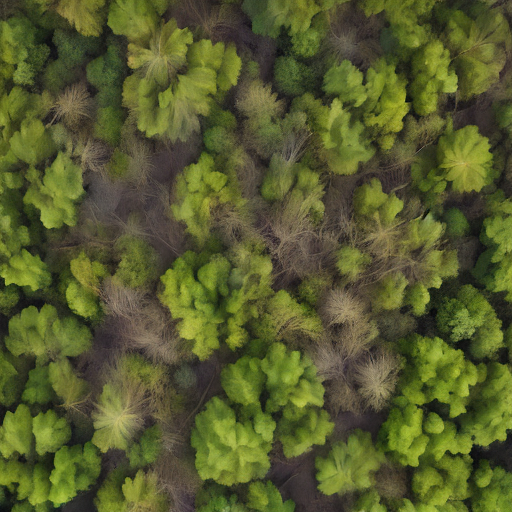

{
  "model_id": "stabilityai/sd-turbo",
  "revision": "b261bac6fd2cf515557d5d0707481eafa0485ec2",
  "prompt": "visual for an ecology lecture series, stylized forest canopy seen from above, layered green shapes, soft morning light, no text, no people",
  "seed": 1022,
  "steps": 1,
  "guidance_scale": 0.0,
  "size": 512,
  "generator_device": "cpu",
  "dtype": "float16",
  "device": "Tesla T4",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "python": "3.13.15",
  "packages": {
    "torch": "2.11.0+cu130",
    "diffusers": "0.40.0",
    "transformers": "5.18.0",
    "pillow": "11.3.0"
  },
  "load_seconds": 30.51,
  "generation_seconds": 0.27,
  "image_size": [
    512,
    512
  ],
  "image_mode": "RGB",
  "sha256": "4a0b8635c62a395b68f8150ff3049c56af43e4e2bf8e206d730570837993d925"
}


In [ ]:
import json
import pathlib
import platform
import sys
import time
import torch
import diffusers
import transformers
import PIL

N = 22
PROMPT = L.BRIEFS[3]
SEED = 1000 + N
STEPS = 1
GUIDANCE = 0.0
SIZE = 512

out = pathlib.Path("artifacts/v22")
out.mkdir(parents=True, exist_ok=True)

start = time.perf_counter()
img = L.generate(pipe, PROMPT, SEED, STEPS, GUIDANCE, SIZE)[0]
generation_s = time.perf_counter() - start

data = L.png_bytes(img)
(out / "result_a.png").write_bytes(data)

manifest = {
    "model_id": L.MODEL_ID,
    "revision": L.REVISION,
    "prompt": PROMPT,
    "seed": SEED,
    "steps": STEPS,
    "guidance_scale": GUIDANCE,
    "size": SIZE,
    "generator_device": "cpu",
    "dtype": "float16",
    "device": torch.cuda.get_device_name(0),
    "platform": platform.platform(),
    "python": sys.version.split()[0],
    "packages": {
        "torch": torch.__version__,
        "diffusers": diffusers.__version__,
        "transformers": transformers.__version__,
        "pillow": PIL.__version__
    },
    "load_seconds": 30.51,
    "generation_seconds": round(generation_s, 2),
    "image_size": list(img.size),
    "image_mode": img.mode,
    "sha256": L.sha(data)
}

(out / "manifest.json").write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2),
    encoding="utf-8"
)

display(img)
print(json.dumps(manifest, ensure_ascii=False, indent=2))

In [ ]:
summary = L.variant_summary(pipe, 22)
print(summary)

{'variant': 22, 'ctx': 4, 'cond': 'dtype', 'seed': 1022, 'sha_a': '4a0b8635c62a395b68f8150ff3049c56af43e4e2bf8e206d730570837993d925', 'sha_b': '83401c691122b3b3178cbb9b3e2f2516ab8da406510cd9327bd5d53930dbd081', 'pixel_equal': False, 'max_diff': 170, 'psnr': np.float64(15.859428156700623), 'verdict': 'different', 'seconds': 1.65, 'psnr_fixed_noise': np.float64(48.51567708211765)}


In [ ]:
import torch

g = torch.Generator(device="cpu").manual_seed(1022)

e1 = pipe(
    prompt=PROMPT,
    num_inference_steps=1,
    guidance_scale=0.0,
    generator=g
).images[0]

e2 = pipe(
    prompt=PROMPT,
    num_inference_steps=1,
    guidance_scale=0.0,
    generator=g
).images[0]

sha1 = L.sha(L.png_bytes(e1))
sha2 = L.sha(L.png_bytes(e2))

print("SHA-256 первого запуска:", sha1)
print("SHA-256 второго запуска:", sha2)
print("SHA совпадают:", sha1 == sha2)
print("PSNR между изображениями:", L.psnr_db(e1, e2), "дБ")

SHA-256 первого запуска: 4a0b8635c62a395b68f8150ff3049c56af43e4e2bf8e206d730570837993d925
SHA-256 второго запуска: 2900b3f1c8037832dbc4453c6c9e921dd47dcfe36319dd2b54d4af83a244ad95
SHA совпадают: False
PSNR между изображениями: 15.554618161515517 дБ


In [ ]:
# Каждый запуск получает новый генератор с тем же seed
fixed1 = L.generate(pipe, PROMPT, 1022)[0]
fixed2 = L.generate(pipe, PROMPT, 1022)[0]

sha_fixed1 = L.sha(L.png_bytes(fixed1))
sha_fixed2 = L.sha(L.png_bytes(fixed2))

print("SHA-256 первого запуска:", sha_fixed1)
print("SHA-256 второго запуска:", sha_fixed2)
print("SHA совпадают:", sha_fixed1 == sha_fixed2)
print("PSNR:", L.psnr_db(fixed1, fixed2), "дБ")

SHA-256 первого запуска: 4a0b8635c62a395b68f8150ff3049c56af43e4e2bf8e206d730570837993d925
SHA-256 второго запуска: 4a0b8635c62a395b68f8150ff3049c56af43e4e2bf8e206d730570837993d925
SHA совпадают: True
PSNR: inf дБ


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

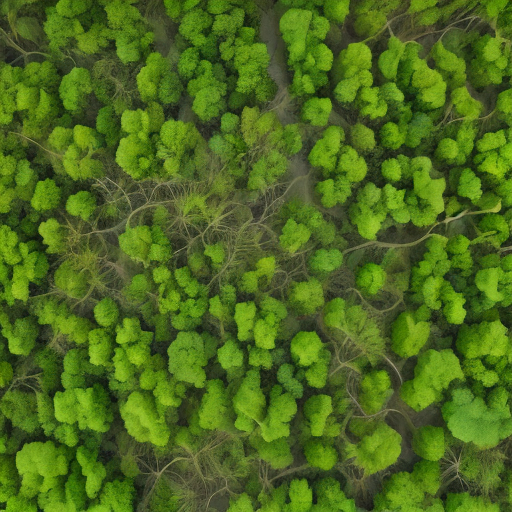

SHA-256 B: aa350b0d01a7c1644f8d99006c92c0e1f9dd795beba8dac73bd6cc7e7a11a4d2


In [ ]:
import torch
import lab05_lib as L
from pathlib import Path
from diffusers import AutoPipelineForText2Image

# Загружаем ту же модель, но с float32
pipe32 = AutoPipelineForText2Image.from_pretrained(
    L.MODEL_ID,
    revision=L.REVISION,
    torch_dtype=torch.float32
).to("cuda")

# Генерируем изображение для условия B
img_b = L.generate(
    pipe32,
    PROMPT,
    SEED,
    STEPS,
    GUIDANCE,
    SIZE
)[0]

# Сохраняем
out_b = Path("artifacts/v22/B")
out_b.mkdir(parents=True, exist_ok=True)

(out_b / "result.png").write_bytes(L.png_bytes(img_b))

display(img_b)

print("SHA-256 B:", L.sha(L.png_bytes(img_b)))

A 4a0b8635c62a395b68f8150ff3049c56af43e4e2bf8e206d730570837993d925


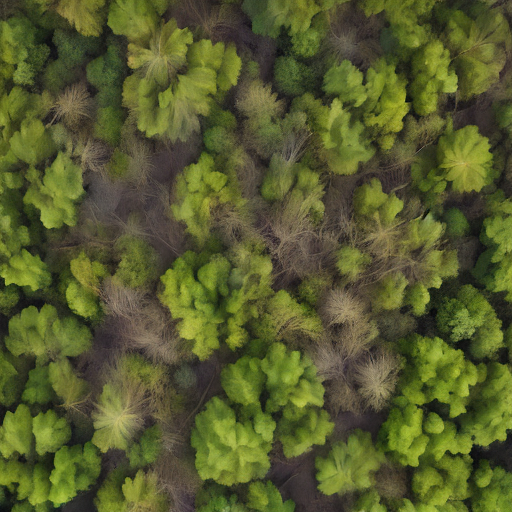

B 83401c691122b3b3178cbb9b3e2f2516ab8da406510cd9327bd5d53930dbd081


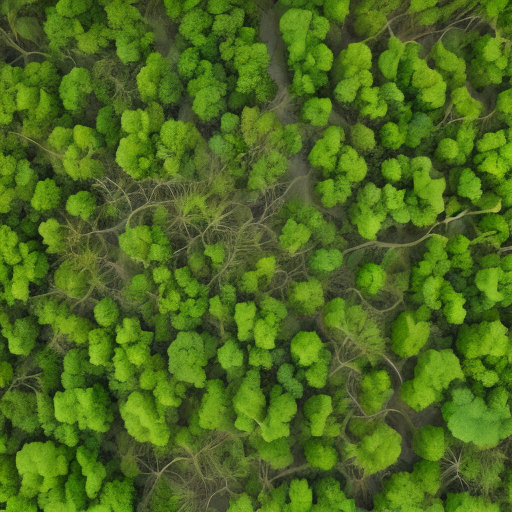

PSNR: 15.859428156700623
Максимальное различие: 170
Совпадение пикселей: False
Вердикт: different


In [ ]:
from pathlib import Path
import json
import torch

# Точная процедура сравнения из учебной библиотеки
a, b = L.make_pair(pipe, L.BRIEFS[3], 1022, "dtype")

base = Path("artifacts/v22")

for name, image, dtype in [
    ("A", a, "float16"),
    ("B", b, "float32"),
]:
    folder = base / name
    folder.mkdir(parents=True, exist_ok=True)

    data = L.png_bytes(image)
    (folder / "result.png").write_bytes(data)

    info = {
        "model_id": L.MODEL_ID,
        "revision": L.REVISION,
        "prompt": L.BRIEFS[3],
        "seed": 1022,
        "steps": 1,
        "guidance_scale": 0.0,
        "size": 512,
        "generator_device": "cpu",
        "dtype": dtype,
        "device": torch.cuda.get_device_name(0),
        "sha256": L.sha(data),
    }

    (folder / "manifest.json").write_text(
        json.dumps(info, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )

    print(name, info["sha256"])
    display(image)

print("PSNR:", L.psnr_db(a, b))
print("Максимальное различие:", L.max_abs_diff(a, b))
print("Совпадение пикселей:", L.psnr_db(a, b) == float("inf"))
print("Вердикт:", L.classify(L.psnr_db(a, b)))